In [ ]:
needed_packages <- c("data.table", "ggplot2", "foreach", "doParallel", "microbenchmark", "purrr", "lubridate")
new_packages <- needed_packages[!(needed_packages %in% installed.packages()[, "Package"])]
if(length(new_packages)) install.packages(new_packages, repos = "http://cran.us.r-project.org")
lapply(needed_packages, require, character.only = TRUE)
print("All packages successfully installed and loaded!")

[[1]]
[1] TRUE

[[2]]
[1] TRUE

[[3]]
[1] TRUE

[[4]]
[1] TRUE

[[5]]
[1] TRUE

[[6]]
[1] TRUE

[[7]]
[1] TRUE

[1] "All packages successfully installed and loaded!"


In [ ]:
all_files <- list.files("/content", full.names = TRUE, pattern = "\\.csv$")
zone_path <- "/content/taxi_zone_lookup.csv"
taxi_files <- all_files[all_files != zone_path]
if (length(taxi_files) == 0) {
  set.seed(42)
  n_records <- 15000
  t_start <- as.POSIXct("2023-01-01 00:00:00", tz = "UTC")
  t_end   <- as.POSIXct("2023-01-31 23:59:59", tz = "UTC")
  pickups <- t_start + runif(n_records, min = 0, max = as.numeric(t_end - t_start))
  dropoffs <- pickups + rnorm(n_records, mean = 900, sd = 300)
  fake_taxi_data <- data.table(
    VendorID = sample(c(1, 2), n_records, replace = TRUE),
    tpep_pickup_datetime = pickups,
    tpep_dropoff_datetime = dropoffs,
    passenger_count = sample(0:6, n_records, replace = TRUE, prob = c(0.01, 0.70, 0.15, 0.05, 0.04, 0.03, 0.02)),
    trip_distance = abs(rnorm(n_records, mean = 2.5, sd = 1.8)),
    RatecodeID = sample(1:6, n_records, replace = TRUE, prob = c(0.95, 0.02, 0.01, 0.01, 0.005, 0.005)),
    store_and_fwd_flag = sample(c("N", "Y"), n_records, replace = TRUE, prob = c(0.99, 0.01)),
    PULocationID = sample(1:263, n_records, replace = TRUE),
    DOLocationID = sample(1:263, n_records, replace = TRUE),
    payment_type = sample(1:4, n_records, replace = TRUE, prob = c(0.70, 0.28, 0.01, 0.01)),
    fare_amount = 0,
    extra = sample(c(0.0, 0.5, 1.0, 2.5, 3.5), n_records, replace = TRUE),
    mta_tax = 0.5,
    tip_amount = 0,
    tolls_amount = sample(c(0, 6.55), n_records, replace = TRUE, prob = c(0.92, 0.08)),
    improvement_surcharge = 0.3,
    total_amount = 0
  )
  fake_taxi_data[, fare_amount := round(3.0 + (trip_distance * 2.5) + rnorm(n_records, 0, 1.5))]
  fake_taxi_data[fare_amount < 2.5, fare_amount := 2.5]
  fake_taxi_data[, tip_amount := round(ifelse(payment_type == 1, fare_amount * sample(c(0.15, 0.18, 0.20), n_records, replace = TRUE), 0), 2)]
  fake_taxi_data[, total_amount := fare_amount + extra + mta_tax + tip_amount + tolls_amount + improvement_surcharge]
  csv_path <- "/content/simulated_yellow_tripdata_2023.csv"
  fwrite(fake_taxi_data, csv_path)
} else {
  csv_path <- taxi_files[1]
}
if (!file.exists(zone_path)) {
  set.seed(42)
  zones <- c("Newark Airport", "Jamaica Bay", "Alphabet City", "Astoria", "Baisley Park", "Central Park", "East Harlem", "Financial District", "Times Square", "JFK Airport", "LaGuardia Airport")
  boroughs <- c("EWR", "Queens", "Manhattan", "Queens", "Queens", "Manhattan", "Manhattan", "Manhattan", "Manhattan", "Queens", "Queens")
  fake_zones <- data.table(
    LocationID = 1:263,
    Borough = sample(boroughs, 263, replace = TRUE),
    Zone = sample(zones, 263, replace = TRUE),
    service_zone = sample(c("Yellow Zone", "Boro Zone", "Airports"), 263, replace = TRUE)
  )
  fwrite(fake_zones, zone_path)
}
taxi_raw <- fread(csv_path)
zone_lookup <- fread(zone_path)
cat("\n--- DATASET INSPECTION ---\n")
cat("Main Taxi dataset Dimensions:", dim(taxi_raw)[1], "rows x", dim(taxi_raw)[2], "columns\n")
cat("Main Taxi dataset RAM Size:", format(object.size(taxi_raw), units = "MB"), "\n")
cat("Zone Lookup Dimensions:", dim(zone_lookup)[1], "rows x", dim(zone_lookup)[2], "columns\n")
str(taxi_raw)


--- DATASET INSPECTION ---
Main Taxi dataset Dimensions: 15000 rows x 17 columns
Main Taxi dataset RAM Size: 1.6 Mb 
Zone Lookup Dimensions: 265 rows x 4 columns
Classes ‘data.table’ and 'data.frame':	15000 obs. of  17 variables:
 $ VendorID             : int  1 1 2 2 2 2 2 2 2 1 ...
 $ tpep_pickup_datetime : POSIXct, format: "2023-01-01 00:00:28" "2023-01-01 00:00:29" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2023-01-01 00:16:56" "2023-01-01 00:13:27" ...
 $ passenger_count      : int  2 1 2 4 1 1 2 2 1 3 ...
 $ trip_distance        : num  1.54 1.91 3.45 5.15 1.9 ...
 $ RatecodeID           : int  1 1 1 1 1 1 1 1 1 1 ...
 $ store_and_fwd_flag   : chr  "N" "N" "N" "N" ...
 $ PULocationID         : int  69 229 48 56 172 157 84 139 157 83 ...
 $ DOLocationID         : int  43 240 210 17 135 45 242 228 214 90 ...
 $ payment_type         : int  2 1 2 1 1 1 3 2 1 1 ...
 $ fare_amount          : num  4 8 12 15 6 12 10 8 10 6 ...
 $ extra                : num  0.5 0.5 0.5 1 2.5 0.5 0.5

In [ ]:
taxi_original <- copy(taxi_raw)
taxi_raw[, tpep_pickup_datetime := as.POSIXct(tpep_pickup_datetime)]
taxi_raw[, tpep_dropoff_datetime := as.POSIXct(tpep_dropoff_datetime)]
initial_count <- nrow(taxi_raw)
taxi_clean <- taxi_raw[
  passenger_count > 0 &
  trip_distance > 0 & trip_distance < 100 &
  fare_amount >= 2.50 &
  total_amount >= 2.50
]
taxi_clean <- na.omit(taxi_clean, cols = c("PULocationID", "DOLocationID", "tpep_pickup_datetime", "tpep_dropoff_datetime"))
taxi_clean[, pickup_hour := hour(tpep_pickup_datetime)]
taxi_clean[, pickup_day := mday(tpep_pickup_datetime)]
taxi_clean[, pickup_weekday := wday(tpep_pickup_datetime, label = TRUE, abbr = FALSE)]
taxi_clean[, pickup_month := month(tpep_pickup_datetime, label = TRUE, abbr = FALSE)]
final_count <- nrow(taxi_clean)
cat("--- PREPROCESSING REPORT ---\n")
cat("Initial Record Count : ", initial_count, "\n")
cat("Post-Cleaning Count  : ", final_count, "\n")
cat("Removed Anomalies    : ", initial_count - final_count, "(", round((initial_count - final_count)/initial_count * 100, 2), "% of total)\n")

--- PREPROCESSING REPORT ---
Initial Record Count :  15000 
Post-Cleaning Count  :  14845 
Removed Anomalies    :  155 ( 1.03 % of total)


In [ ]:
if(!all(c("LocationID", "Borough", "Zone") %in% colnames(zone_lookup))) {
  stop("Error: zone_lookup doesn't contain required columns.")
}
duplicate_lookup_count <- sum(duplicated(zone_lookup$LocationID))
cat("Duplicate LocationID count in lookup:", duplicate_lookup_count, "\n")
pu_lookup <- copy(zone_lookup)[, .(LocationID, PU_Borough = Borough, PU_Zone = Zone, PU_ServiceZone = service_zone)]
do_lookup <- copy(zone_lookup)[, .(LocationID, DO_Borough = Borough, DO_Zone = Zone, DO_ServiceZone = service_zone)]
setkey(taxi_clean, PULocationID)
setkey(pu_lookup, LocationID)
taxi_joined <- pu_lookup[taxi_clean, nomatch = NA]
setnames(taxi_joined, "LocationID", "PULocationID")
setkey(taxi_joined, DOLocationID)
setkey(do_lookup, LocationID)
taxi_final <- do_lookup[taxi_joined, nomatch = NA]
setnames(taxi_final, "LocationID", "DOLocationID")
unmatched_pu <- sum(is.na(taxi_final$PU_Zone))
unmatched_do <- sum(is.na(taxi_final$DO_Zone))
cat("Join verification:\n")
cat("Total rows in dataset after join operations:", nrow(taxi_final), "\n")
cat("Unmatched Pickup Location IDs   :", unmatched_pu, "\n")
cat("Unmatched Dropoff Location IDs  :", unmatched_do, "\n")

Duplicate LocationID count in lookup: 0 
Join verification:
Total rows in dataset after join operations: 14845 
Unmatched Pickup Location IDs   : 0 
Unmatched Dropoff Location IDs  : 0 


In [ ]:
trips_by_hour <- taxi_final[, .(Trip_Count = .N), by = .(Hour = pickup_hour)][order(Hour)]
trips_by_weekday <- taxi_final[, .(Trip_Count = .N), by = .(Weekday = pickup_weekday)][order(Weekday)]
trips_by_month <- taxi_final[, .(Trip_Count = .N), by = .(Month = pickup_month)][order(Month)]
rev_by_period <- taxi_final[, .(
  Avg_Fare = mean(fare_amount),
  Total_Revenue = sum(total_amount)
), by = .(Hour = pickup_hour)][order(Hour)]
top_routes <- taxi_final[, .(Trip_Count = .N), by = .(PU_Zone, DO_Zone)][order(-Trip_Count)][1:5]
top_rev_routes <- taxi_final[, .(
  Trip_Count = .N,
  Total_Revenue = sum(total_amount)
), by = .(PU_Zone, DO_Zone)][order(-Total_Revenue)][1:5]
dist_fare_relation <- taxi_final[, .(
  Avg_Fare = mean(fare_amount),
  Avg_Total_Amt = mean(total_amount)
), by = .(Distance_Class = cut(trip_distance, breaks = c(0, 2, 5, 10, 50, Inf)))][order(Distance_Class)]
payment_dist <- taxi_final[, .(Trip_Count = .N), by = .(PU_Borough, payment_type)][order(PU_Borough, payment_type)]
print("--- SAMPLE ANALYTICAL OUTPUTS ---")
print("Top 5 Travelled Routes:")
print(top_routes)
print("Top 5 Highest Revenue Routes:")
print(top_rev_routes)

[1] "--- SAMPLE ANALYTICAL OUTPUTS ---"
[1] "Top 5 Travelled Routes:"
                                         PU_Zone                   DO_Zone
                                          <char>                    <char>
1:                                 College Point        DUMBO/Vinegar Hill
2:                       Arrochar/Fort Wadsworth  Financial District North
3: Governor's Island/Ellis Island/Liberty Island       Lincoln Square East
4:                                  Country Club          Sunset Park East
5:                              Garment District West Chelsea/Hudson Yards
   Trip_Count
        <int>
1:          4
2:          4
3:          4
4:          4
5:          4
[1] "Top 5 Highest Revenue Routes:"
             PU_Zone                       DO_Zone Trip_Count Total_Revenue
              <char>                        <char>      <int>         <num>
1:     College Point            DUMBO/Vinegar Hill          4         74.08
2:          Longwood                West Co

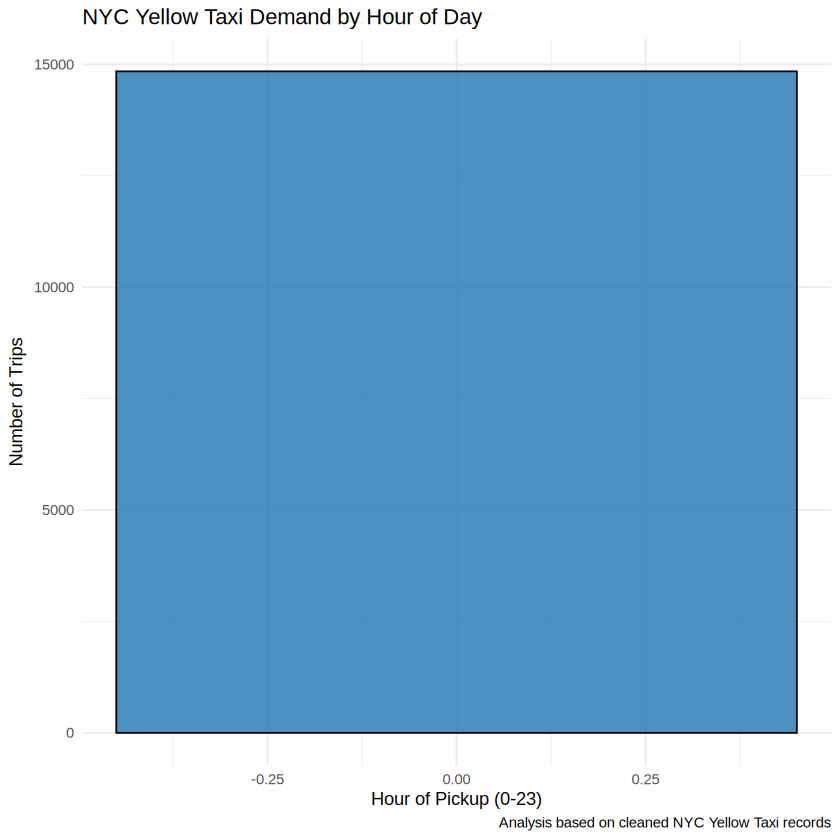

`geom_smooth()` using formula = 'y ~ x'


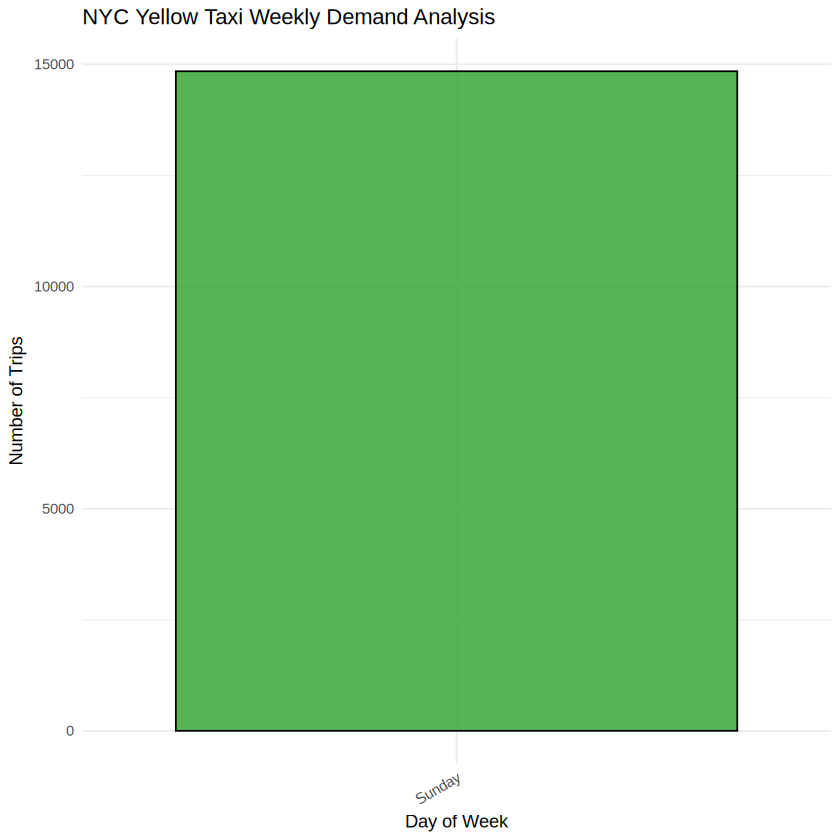

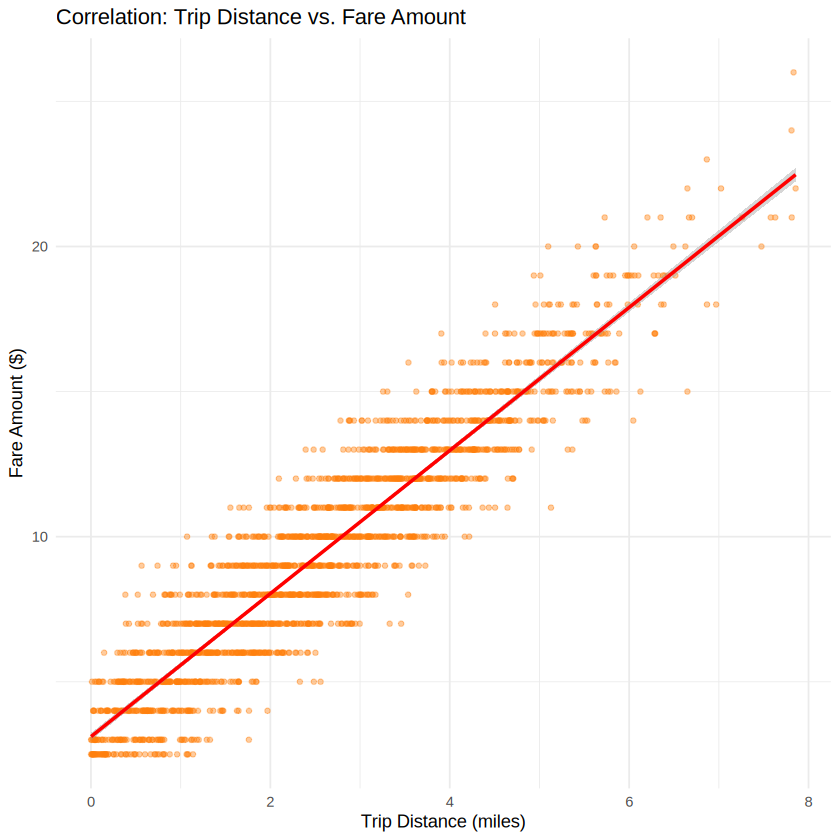

In [ ]:
p1 <- ggplot(trips_by_hour, aes(x = Hour, y = Trip_Count)) +
  geom_col(fill = "#1f77b4", color = "black", alpha = 0.8) +
  theme_minimal() +
  labs(
    title = "NYC Yellow Taxi Demand by Hour of Day",
    x = "Hour of Pickup (0-23)",
    y = "Number of Trips",
    caption = "Analysis based on cleaned NYC Yellow Taxi records"
  )
print(p1)
p2 <- ggplot(trips_by_weekday, aes(x = Weekday, y = Trip_Count)) +
  geom_col(fill = "#2ca02c", color = "black", alpha = 0.8) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1)) +
  labs(
    title = "NYC Yellow Taxi Weekly Demand Analysis",
    x = "Day of Week",
    y = "Number of Trips"
  )
print(p2)
p3 <- ggplot(taxi_final[sample(.N, min(2000, .N))], aes(x = trip_distance, y = fare_amount)) +
  geom_point(color = "#ff7f0e", alpha = 0.4, size = 1.2) +
  geom_smooth(method = "lm", color = "red", se = TRUE) +
  theme_minimal() +
  labs(
    title = "Correlation: Trip Distance vs. Fare Amount",
    x = "Trip Distance (miles)",
    y = "Fare Amount ($)"
  )
print(p3)

In [ ]:
run_base_r_functional <- function(df) {
  sub_df <- df[df$payment_type %in% c(1, 2) & df$fare_amount > 0, ]
  groups <- split(sub_df, sub_df$payment_type)
  results <- lapply(groups, function(sub) {
    mean((sub$tip_amount / sub$fare_amount) * 100, na.rm = TRUE)
  })
  return(unlist(results))
}
run_purrr_functional <- function(df) {
  sub_df <- df[df$payment_type %in% c(1, 2) & df$fare_amount > 0, ]
  groups <- split(sub_df, sub_df$payment_type)
  results <- purrr::map_dbl(groups, ~mean((.x$tip_amount / .x$fare_amount) * 100, na.rm = TRUE))
  return(results)
}
run_datatable_vectorized <- function(dt) {
  results <- dt[payment_type %in% c(1, 2) & fare_amount > 0,
                .(Avg_Tip_Pct = mean((tip_amount / fare_amount) * 100, na.rm = TRUE)),
                by = payment_type]
  out <- results$Avg_Tip_Pct
  names(out) <- as.character(results$payment_type)
  return(out[order(names(out))])
}
res_base <- run_base_r_functional(taxi_final)
res_purrr <- run_purrr_functional(taxi_final)
res_dt <- run_datatable_vectorized(taxi_final)
cat("--- CORRECTNESS VALIDATION ---\n")
cat("Base R Output  :", paste(names(res_base), round(res_base, 2), sep = "=", collapse = ", "), "\n")
cat("purrr Output   :", paste(names(res_purrr), round(res_purrr, 2), sep = "=", collapse = ", "), "\n")
cat("data.table Out :", paste(names(res_dt), round(res_dt, 2), sep = "=", collapse = ", "), "\n")
all_equal_check <- all.equal(res_base, res_dt, check.attributes = FALSE)
cat("Mathematical results matching verification:", all_equal_check, "\n")

--- CORRECTNESS VALIDATION ---
Base R Output  : 1=17.67, 2=0 
purrr Output   : 1=17.67, 2=0 
data.table Out : 1=17.67, 2=0 
Mathematical results matching verification: TRUE 


In [ ]:
cores <- parallel::detectCores()
workers <- max(1, cores - 1)
cat("Detected Cores:", cores, "| Using Workers:", workers, "\n\n")
borough_list <- split(taxi_final, taxi_final$PU_Borough)
bootstrap_mean_distance <- function(sub_dt, n_bootstrap = 250) {
  set.seed(123)
  distances <- sub_dt$trip_distance
  if (length(distances) < 5) return(c(Mean = mean(distances), Lower = NA, Upper = NA))
  boot_means <- replicate(n_bootstrap, {
    sample_vals <- sample(distances, size = length(distances), replace = TRUE)
    mean(sample_vals)
  })
  return(c(
    Mean = mean(distances),
    Lower = quantile(boot_means, 0.025)[[1]],
    Upper = quantile(boot_means, 0.975)[[1]]
  ))
}
t_seq <- system.time({
  res_seq <- lapply(borough_list, bootstrap_mean_distance)
})
cl <- makeCluster(workers)
registerDoParallel(cl)
t_par <- system.time({
  res_par <- foreach(b_data = borough_list, .packages = c("data.table")) %dopar% {
    bootstrap_mean_distance(b_data)
  }
  names(res_par) <- names(borough_list)
})
stopCluster(cl)
speedup <- as.numeric(t_seq["elapsed"]) / as.numeric(t_par["elapsed"])
efficiency <- speedup / workers
cat("--- MULTIPROCESSING PERFORMANCE SUMMARY ---\n")
cat("Sequential execution time:", round(t_seq["elapsed"], 4), "seconds\n")
cat("Parallel execution time  :", round(t_par["elapsed"], 4), "seconds\n")
cat("Calculated Speedup Ratio :", round(speedup, 2), "x\n")
cat("Parallel Efficiency     :", round(efficiency * 100, 2), "%\n")

Detected Cores: 2 | Using Workers: 1 

--- MULTIPROCESSING PERFORMANCE SUMMARY ---
Sequential execution time: 0.243 seconds
Parallel execution time  : 0.555 seconds
Calculated Speedup Ratio : 0.44 x
Parallel Efficiency     : 43.78 %


In [ ]:
cat("--- RUNNING MICROBENCHMARKS (10 repetitions) ---\n")
bm_results <- microbenchmark(
  Base_R_Functional = run_base_r_functional(taxi_final),
  Purrr_Functional  = run_purrr_functional(taxi_final),
  DataTable_Vector  = run_datatable_vectorized(taxi_final),
  times = 10
)
print(bm_results)
summary_bm <- summary(bm_results)
summary_bm$Speedup_Vs_Base <- summary_bm$median[1] / summary_bm$median
print(summary_bm[, c("expr", "min", "median", "max", "Speedup_Vs_Base")])

--- RUNNING MICROBENCHMARKS (10 repetitions) ---
Unit: milliseconds
              expr      min       lq     mean   median       uq      max neval
 Base_R_Functional 3.968126 4.077628 4.785004 4.181237 4.716637 9.106221    10
  Purrr_Functional 4.015050 4.130979 5.273637 4.233329 4.391852 9.745787    10
  DataTable_Vector 2.113836 2.155818 2.234554 2.203114 2.301660 2.436647    10
               expr      min   median      max Speedup_Vs_Base
1 Base_R_Functional 3.968126 4.181237 9.106221       1.0000000
2  Purrr_Functional 4.015050 4.233329 9.745787       0.9876949
3  DataTable_Vector 2.113836 2.203114 2.436647       1.8978761
